In [14]:
import numpy as np
import matplotlib.pyplot as plt
from labellines import labelLines
from matplotlib.patches import Patch

In [15]:
n = 10
x = np.linspace(0, 1, 1000)
y = np.linspace(0, n, 1000)
X, Y = np.meshgrid(x, y)

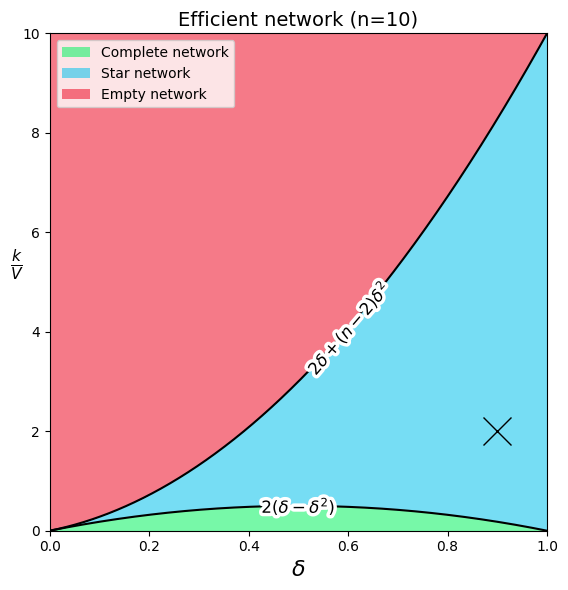

In [16]:
def f1(x, n):
    return 2 * (x - x**2), r"$2(\delta-\delta^2)$"

def f2(x, n):
    return 2 * x + (n - 2) * x**2, r"$2\delta+(n-2)\delta^2$"

# Compute each curve once
y1, label1 = f1(x, n)
y2, label2 = f2(x, n)

# Broadcast 1D curves across the 2D grid
F1 = y1[None, :]
F2 = y2[None, :]

# -----------------------------
# Region classification
# -----------------------------
Z = np.zeros_like(Y, dtype=int)
Z[Y >= F1] = 1
Z[Y >= F2] = 2

# -----------------------------
# Plot
# -----------------------------
fig, ax = plt.subplots(figsize=(6, 6))

region_colors = ["#07f362", "#06c2ec", "#ee0d27"]
region_labels = ["Complete network", "Star network", "Empty network"]
contour = ax.contourf(
    X, Y, Z,
    levels=[-0.5, 0.5, 1.5, 2.5],
    colors=region_colors,
    alpha=0.55
)

line1, = ax.plot(x, y1, color="black", label=label1)
line2, = ax.plot(x, y2, color="black", label=label2)

# Automatic line labels
labelLines([line1, line2], xvals=[0.50, 0.6], fontsize=12)

# Region legend
legend_handles = [
    Patch(facecolor=color, edgecolor="none", alpha=0.55, label=label)
    for color, label in zip(region_colors, region_labels)
]
ax.legend(handles=legend_handles, loc="upper left", frameon=True)

# Axes / title
ax.set_xlim(0, 1)
ax.set_ylim(0, n)
ax.set_xlabel(r"$\delta$", size=16)
ax.set_ylabel(r"$\frac{k}{V}$", rotation=0, size=16)
ax.set_box_aspect(1)

# Linking game parameters
ax.plot(0.9, (n * 2) / 10, 'x', color='black', markersize=20)

ax.set_title(f"Efficient network (n={n})", size=14)
plt.tight_layout()
plt.show()

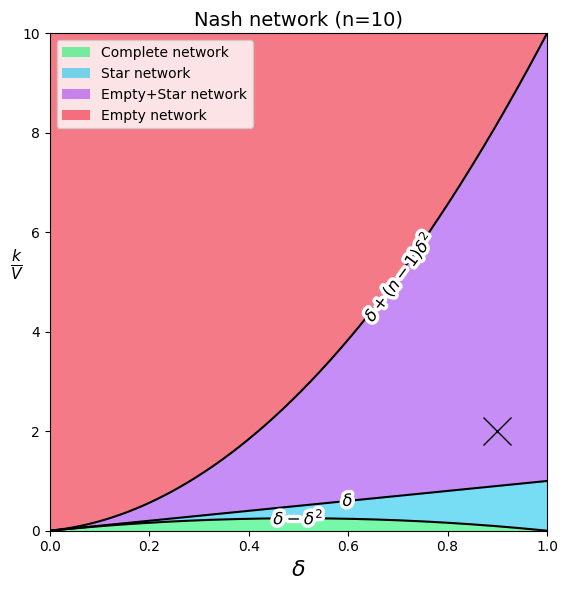

In [17]:
def f1(x, n):
    return x - x**2, r"$\delta-\delta^2$"

def f2(x, n):
    return x, r"$\delta$"

def f3(x, n):
    return x + (n - 1) * x**2, r"$\delta+(n-1)\delta^2$"

# Compute each curve once
y1, label1 = f1(x, n)
y2, label2 = f2(x, n)
y3, label3 = f3(x, n)

# Broadcast 1D curves across the 2D grid
F1 = y1[None, :]
F2 = y2[None, :]
F3 = y3[None, :]

# -----------------------------
# Region classification
# -----------------------------
Z = np.zeros_like(Y, dtype=int)
Z[Y >= F1] = 1
Z[Y >= F2] = 2
Z[Y >= F3] = 3


# -----------------------------
# Plot
# -----------------------------
fig, ax = plt.subplots(figsize=(6, 6))

region_colors = ["#07f362", "#06c2ec", "#9a30f0", "#ee0d27"]
region_labels = ["Complete network", "Star network", "Empty+Star network", "Empty network"]
contour = ax.contourf(
    X, Y, Z,
    levels=[-0.5, 0.5, 1.5, 2.5, 3.5],
    colors=region_colors,
    alpha=0.55
)

line1, = ax.plot(x, y1, color="black", label=label1)
line2, = ax.plot(x, y2, color="black", label=label2)
line3, = ax.plot(x, y3, color="black", label=label3)

# Automatic line labels
labelLines([line1, line2, line3], xvals=[0.50, 0.6, 0.7], fontsize=12)

# Region legend
legend_handles = [
    Patch(facecolor=color, edgecolor="none", alpha=0.55, label=label)
    for color, label in zip(region_colors, region_labels)
]
ax.legend(handles=legend_handles, loc="upper left", frameon=True)

# Axes / title
ax.set_xlim(0, 1)
ax.set_ylim(0, n)
ax.set_xlabel(r"$\delta$", size=16)
ax.set_ylabel(r"$\frac{k}{V}$", rotation=0, size=16)
ax.set_box_aspect(1)

# Linking game parameters
ax.plot(0.9, (n * 2) / 10, 'x', color='black', markersize=20)

ax.set_title(f"Nash network (n={n})", size=14)
plt.tight_layout()
plt.show()